<a href="https://colab.research.google.com/github/viriescence/cancer-dgea-tool/blob/main/CancerGeneReg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!apt-get update -qq
!apt-get install -y -qq libcurl4-openssl-dev libssl-dev libxml2-dev
%pip install -q rpy2 # R conversion package for Colab
%load_ext rpy2.ipython

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [2]:
from google.colab import drive
import pandas as pd

drive.mount("/content/drive")
D = "/content/drive/MyDrive/cancer-dgea-data"

project = "TCGA-BRCA"
expr   = pd.read_csv(f"{D}/{project}_logcpm.csv.gz", index_col=0)   # genes x samples
groups = pd.read_csv(f"{D}/{project}_groups.csv")
genes  = pd.read_csv(f"{D}/{project}_genes.csv")

Mounted at /content/drive


In [ ]:
%%R

# Install BiocManager into the persistent library
install.packages(
  "BiocManager",
  lib = R_LIB,
  repos = "https://cloud.r-project.org"
)

# Force the Bioconductor packages into the persistent library
BiocManager::install(
  c(
    "TCGAbiolinks",
    "SummarizedExperiment",
    "edgeR"
  ),
  lib = R_LIB,
  force = TRUE,
  dependencies = TRUE,
  ask = FALSE,
  update = FALSE,
  Ncpus = 2
)

trying URL 'https://cloud.r-project.org/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB


The downloaded source packages are in
	‘/tmp/RtmpSz2OTR/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)
Installing package(s) 'TCGAbiolinks', 'SummarizedExperiment', 'edgeR'
also installing the dependencies ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘fontBitstreamVera’, ‘fontLiberation’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘fontquiver’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘formatR’, ‘gridGraphics’, ‘gdtools’, ‘tweenr’, ‘polyclip’, ‘deldir’, ‘carData’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘litedown’, ‘lambda.r’, ‘futile.options’, ‘di

In [4]:
%%R

# This cell is to check if the data is in the correct directory

R_LIB <- "/content/drive/MyDrive/cancer-dgea-data/R-library"

.libPaths(c(R_LIB, .libPaths()))

print(.libPaths())

packages <- c(
  "TCGAbiolinks",
  "SummarizedExperiment",
  "edgeR"
)

sapply(
  packages,
  function(pkg) {
    find.package(
      pkg,
      lib.loc = R_LIB,
      quiet = TRUE
    )
  }
)

[1] "/content/drive/.shortcut-targets-by-id/11MrVovYZJdVUsAYYrIe-5YqqH185GU4O/cancer-dgea-data/R-library"
[2] "/usr/local/lib/R/site-library"                                                                      
[3] "/usr/lib/R/site-library"                                                                            
[4] "/usr/lib/R/library"                                                                                 
$TCGAbiolinks
character(0)

$SummarizedExperiment
character(0)

$edgeR
character(0)



In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

"""
Analyze differential gene expression for one TCGA project.

Reads a log2-CPM expression matrix, sample-group labels, and gene annotations.
Aligns tumor and normal samples, calculates per gene log2 fold changes,
performs Welch's two sample t tests, applies Benjamini-Hochberg multiple-testing
correction, and labels genes as upregulated, downregulated, or not significant.ImportError

Saves:
  A ranked gene table as a CSV file
  A volcano plot as a PNG file

Parameters
project : str
  TCGA project identifier, such as "TCGA-BRCA"

data_dir : str
  Directory containing the exported expression, group, and gene
  annotation files.

Returns
--------
pandas.DataFrame
Complete per gene results table containing fold changes,
t test statistics, p-values, adjusted p-values, annotations,
and significant status.

"""
def analyze_project(project, data_dir=D):
  # -----------------------------
  # Read files
  # -----------------------------
  expr = pd.read_csv(f"{data_dir}/{project}_logcpm.csv.gz",
        index_col=0
  )

  # Sample IDs are sold as the first column/index
  groups = pd.read_csv(
      f"{data_dir}/{project}_groups.csv",
      index_col=0
  )

  genes = pd.read_csv(
      f"{data_dir}/{project}_genes.csv"
  )

  expr.columns = expr.columns.astype(str)
  groups.index = groups.index.astype(str)
  groups.index.name = "sample_id"

  # Confirm every expression sample as a group labe;
  missing = set(expr.columns) - set(groups.index)

  if missing:
    raise ValueError(
        f"Missing group labels for samples: {list(missing)[:10]}"
    )

  # Match group order to expression-matrix columns
  groups_aligned = groups.loc[expr.columns]

  normal_samples = groups_aligned.index[
      groups_aligned["group"] == "normal"
  ]

  tumor_samples = groups_aligned.index[
        groups_aligned["group"] == "tumor"
  ]

  print(f"{project}:")
  print(f" Nromal samples: {len(normal_samples)}")
  print(f" Tumor samples: {len(tumor_samples)}")
  print(f" Genes: {expr.shape[0]}")

  # -----------------------------
  # Log2 fold change
  # -----------------------------
  mean_normal = expr[normal_samples].mean(axis=1)
  mean_tumor = expr[tumor_samples].mean(axis=1)

  # Expression is already log2
  log2fc = mean_tumor - mean_normal

  # -----------------------------
  # Per gene welch t tests
  # -----------------------------
  tumor_values = expr[tumor_samples].to_numpy(dtype=float)
  normal_values = expr[normal_samples].to_numpy(dtype=float)

  t_statistic, p_value = ttest_ind(
      tumor_values,
      normal_values,
      axis=1,
      equal_var=False,
      nan_policy="omit"
  )

  p_value = np.nan_to_num(
      p_value,
      nan=1.0,
      posinf=1.0,
      neginf=1.0
  )

  # -----------------------------
  # Benjamini Hochberg correction
  # -----------------------------
  padj = multipletests(
      p_value,
      method="fdr_bh"
  )[1]

  # -----------------------------
  # Creating a ranked table
  # -----------------------------
  results = pd.DataFrame({
      "gene_id": expr.index.astype(str),
      "mean_normal": mean_normal.to_numpy(),
      "mean_tumor": mean_tumor.to_numpy(),
      "log2FC": log2fc.to_numpy(),
      "t_statistic": t_statistic,
      "p_value": p_value,
      "padj": padj
  })

  genes["gene_id"] = genes["gene_id"].astype(str)

  results = results.merge(
      genes[["gene_id", "gene_name", "gene_type"]].drop_duplicates(
          "gene_id"
      ),
      on="gene_id",
      how="left"
  )

  # Significance categories
  FDR_THRESHOLD = 0.05
  LOG2FC_THRESHOLD = 1.0

  results["status"] = "not_significant"

  results.loc[
      (results["padj"] < FDR_THRESHOLD) &
      (results["log2FC"] <= -LOG2FC_THRESHOLD),
      "status"
  ] = "down"

  # Rank by adjusted p-value
  results["absolute_log2FC"] = results["log2FC"].abs()

  results = results.sort_values(
      by=["padj", "absolute_log2FC"],
      ascending=[True, False]
  ).reset_index(drop=True)

  # -----------------------------
  # Saving the ranked table
  # -----------------------------
  table_dir = f"{data_dir}/results/tables"
  figure_dir = f"{data_dir}/results/figures"

  os.makedirs(table_dir, exist_ok=True)
  os.makedirs(figure_dir, exist_ok=True)

  ranked_table = results[
      [
          "gene_id",
          "gene_name",
          "log2FC",
          "p_value",
          "padj",
          "status"
      ]
  ]

  table_path = f"{table_dir}/{project}_ranked_genes.csv"
  ranked_table.to_csv(table_path, index=False)

  print(f"Saved ranked table to: {table_path}")
  display(ranked_table.head(20))

  # -----------------------------
  # Volcano plot
  # -----------------------------
  plot_data = results.copy()

  plot_data["log2FC"] = pd.to_numeric(
      plot_data["log2FC"],
      errors="coerce"
  )

  plot_data["padj"] = pd.to_numeric(
      plot_data["padj"],
      errors="coerce"
  )

  plot_data = plot_data[
      np.isfinite(plot_data["log2FC"]) &
      np.isfinite(plot_data["padj"])
  ].copy()

  plot_data["minus_log10_padj"] = -np.log10(
      plot_data["padj"].clip(lower=np.finfo(float).tiny)
  )

  # Check that plotting data actually exist
  print("Genes being plotted:", len(plot_data))
  print(plot_data["status"].value_counts())
  print("Log2FC range:", plot_data["log2FC"].min(),
        "to", plot_data["log2FC"].max())
  print("-log10(padj) range:", plot_data["minus_log10_padj"].min(),
        "to", plot_data["minus_log10_padj"].max())

  # Divide points into categories
  up = plot_data[plot_data["status"] == "up"]
  down = plot_data[plot_data["status"] == "down"]
  not_significant = plot_data[
      plot_data["status"] == "not_significant"
  ]

  fig, ax = plt.subplots(figsize=(11, 8))

  ax.scatter(
      not_significant["log2FC"],
      not_significant["minus_log10_padj"],
      color="lightgray",
      s=10,
      alpha=0.5,
      label="not significant"
  )

  ax.scatter(
      up["log2FC"],
      up["minus_log10_padj"],
      color="firebrick",
      s=14,
      alpha=0.7,
      label="up"
  )

  ax.scatter(
      down["log2FC"],
      down["minus_log10_padj"],
      color="royalblue",
      s=14,
      alpha=0.7,
      label="down"
  )

  # Threshold lines
  ax.axvline(
      1,
      color="black",
      linestyle="--",
      linewidth=1
  )

  ax.axvline(
      -1,
      color="black",
      linestyle="--",
      linewidth=1
  )

  ax.axhline(
      -np.log10(0.05),
      color="black",
      linestyle="--",
      linewidth=1
  )

  ax.set_title(
      f"{project}: Tumor vs. Normal Differential Expression"
  )

  ax.set_xlabel("Log2 fold change")
  ax.set_ylabel("-Log10 adjusted p-value")
  ax.legend()

  plt.tight_layout()

  figure_path = (
      f"{data_dir}/results/figures/"
      f"{project}_volcano_plot.png"
  )

  plt.savefig(
      figure_path,
      dpi=300,
      bbox_inches="tight"
  )

  plt.show()

  print("\n")

  print(f"Saved volcano plot to: {figure_path}")

  return results


TCGA-BRCA:
 Nromal samples: 113
 Tumor samples: 1095
 Genes: 15319
Saved ranked table to: /content/drive/MyDrive/cancer-dgea-data/results/tables/TCGA-BRCA_ranked_genes.csv


,gene_id,gene_name,log2FC,p_value,padj,status
0,ENSG00000132561.14,MATN2,-3.337718,6.067256e-224,9.294430e-220,down
1,ENSG00000145777.15,TSLP,-4.182335,4.957638e-188,3.797303e-184,down
2,ENSG00000148053.17,NTRK2,-4.058276,4.151863e-187,2.120080e-183,down
3,ENSG00000147862.17,NFIB,-2.282988,1.224201e-177,4.688383e-174,down
4,ENSG00000189369.9,GSPT2,-1.604585,4.247666e-176,1.301400e-172,down
5,ENSG00000136158.12,SPRY2,-2.831282,6.923232e-173,1.767617e-169,down
6,ENSG00000177098.9,SCN4B,-3.077800,3.965101e-166,8.677339e-163,down
7,ENSG00000146648.19,EGFR,-3.079875,9.699662e-164,1.857364e-160,down
8,ENSG00000137033.11,IL33,-3.809445,1.847368e-160,3.144426e-157,down
9,ENSG00000119147.10,ECRG4,-5.001459,4.855564e-157,7.438238e-154,down


Genes being plotted: 15319
status
not_significant    12951
down                2368
Name: count, dtype: int64
Log2FC range: -7.456101889521962 to 6.8235011920636905
-log10(padj) range: 0.00015745944675233723 to 219.03177725301103


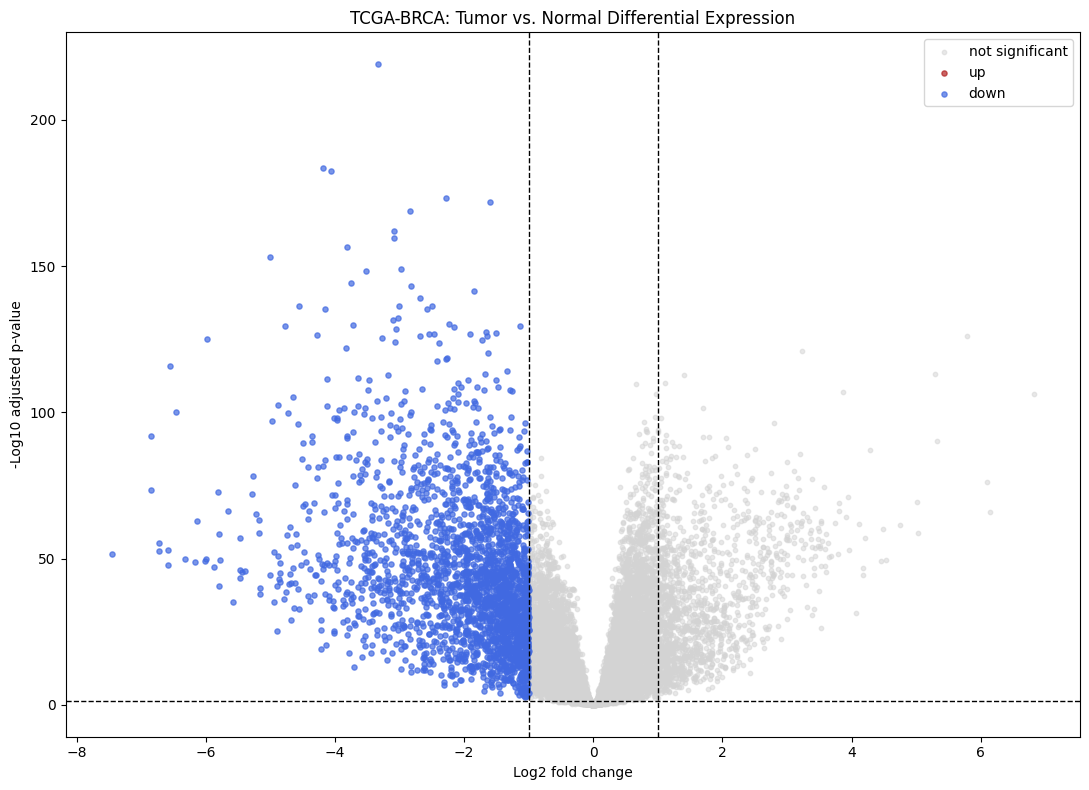



Saved volcano plot to: /content/drive/MyDrive/cancer-dgea-data/results/figures/TCGA-BRCA_volcano_plot.png


In [21]:
brca_results = analyze_project("TCGA-BRCA")

TCGA-LUAD:
 Nromal samples: 59
 Tumor samples: 517
 Genes: 15539
Saved ranked table to: /content/drive/MyDrive/cancer-dgea-data/results/tables/TCGA-LUAD_ranked_genes.csv


,gene_id,gene_name,log2FC,p_value,padj,status
0,ENSG00000168484.12,SFTPC,-8.476784,4.203656e-170,6.532061e-166,down
1,ENSG00000066405.13,CLDN18,-6.932630,9.708530e-170,7.543043e-166,down
2,ENSG00000168481.9,LGI3,-6.733127,4.215625e-160,2.183553e-156,down
3,ENSG00000134115.13,CNTN6,-4.996063,6.786511e-150,2.636390e-146,down
4,ENSG00000204305.14,AGER,-6.598702,9.972035e-144,3.099109e-140,down
5,ENSG00000112782.19,CLIC5,-4.559705,1.165884e-137,3.019444e-134,down
6,ENSG00000171885.18,AQP4,-4.672813,1.524404e-125,3.383960e-122,down
7,ENSG00000099994.11,SUSD2,-3.497849,2.770346e-122,5.381051e-119,down
8,ENSG00000102104.9,RS1,-5.296210,3.996656e-120,6.864475e-117,down
9,ENSG00000115361.8,ACADL,-4.265829,4.417578e-120,6.864475e-117,down


Genes being plotted: 15539
status
not_significant    13210
down                2329
Name: count, dtype: int64
Log2FC range: -8.476783975346684 to 6.170518516211523
-log10(padj) range: 0.0005372912070975273 to 165.18494977244214


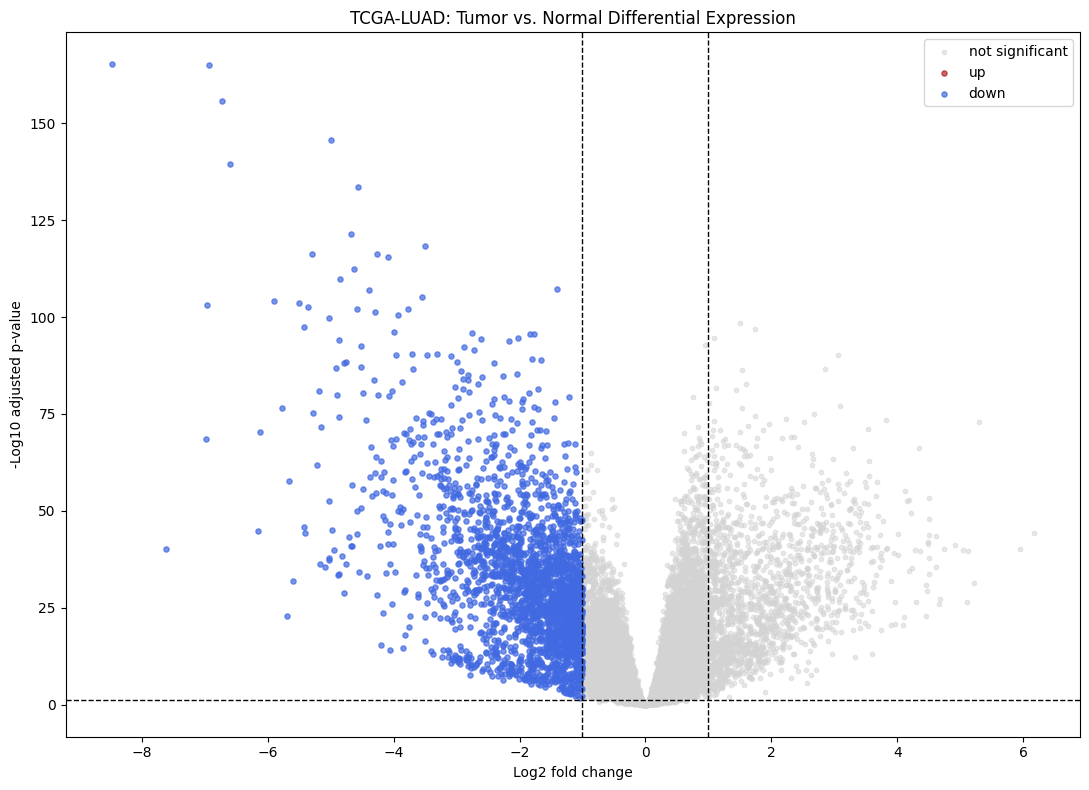



Saved volcano plot to: /content/drive/MyDrive/cancer-dgea-data/results/figures/TCGA-LUAD_volcano_plot.png


In [22]:
luad_results = analyze_project("TCGA-LUAD")